# Jordan Lake Spatiotemporal Simulation
ASV wind characterization simulation at the Jordan Lake mission domain.

Features:
- STGPKF Formulation
    - Generate Synthetic Data
    - Make estimates based upon existing measurements
- Ergodic Control
- Real-Time SOC-Based speed control
- Hyperparameter Estimation

In [29]:
# Import Packages
using Logging: global_logger
using TerminalLoggers: TerminalLogger
global_logger(TerminalLogger())

using ProgressLogging

using LinearAlgebra
using Random
using Statistics
using Plots
using LaTeXStrings
using Revise
using StaticArrays
using Interpolations
using LazySets

In [30]:
# Import modules
include("../../../src/jordan_lake_domain.jl")
include("../../../src/stgpkf.jl")
include("../../../src/kf.jl")
include("../../../src/ngpkf.jl")
include("../../../src/SyntheticData.jl")
include("../../../src/ergodic.jl")
include("../../../src/variograms.jl")
include("../../../src/SOC_Controller.jl")
include("../../../src/simulator_spatial.jl")
include("../../../src/simulator_ST.jl")
include("../../../src/Convex_bound_avoidance.jl")

┌ Warning: Replacing docs for Main.Variograms.hp_fit :: Tuple{Any} in module
│ Main.Variograms
└ @ Base.Docs docs/Docs.jl:243


Main.ConvexBoundAvoidance

In [31]:
JordanLakeDomain.grid_mesh

387-element Vector{Vector{Float64}}:
 [0.03979999999999995, 0.0]
 [0.18979999999999994, 0.0]
 [0.33979999999999994, 0.0]
 [0.4897999999999999, 0.0]
 [0.6397999999999999, 0.0]
 [0.7898, 0.0]
 [0.9397999999999999, 0.0]
 [1.0897999999999999, 0.0]
 [1.2397999999999998, 0.0]
 [0.03979999999999995, 0.15]
 ⋮
 [0.03979999999999995, 6.3]
 [0.18979999999999994, 6.3]
 [0.33979999999999994, 6.3]
 [0.4897999999999999, 6.3]
 [0.6397999999999999, 6.3]
 [0.7898, 6.3]
 [0.9397999999999999, 6.3]
 [1.0897999999999999, 6.3]
 [1.2397999999999998, 6.3]

In [32]:
JordanLakeDomain.meshx

9-element Vector{Float64}:
 0.03979999999999995
 0.18979999999999994
 0.33979999999999994
 0.4897999999999999
 0.6397999999999999
 0.7898
 0.9397999999999999
 1.0897999999999999
 1.2397999999999998

In [33]:
JordanLakeDomain.meshy

43-element Vector{Float64}:
 0.0
 0.15
 0.3
 0.45
 0.6
 0.75
 0.9
 1.05
 1.2
 1.35
 ⋮
 5.1
 5.25
 5.4
 5.55
 5.7
 5.85
 6.0
 6.15
 6.3

# Generate Synthetic Data

In [34]:
# Define simulation time-scale/steps
Δt = 2.5 # seconds
dt_hrs = Δt/(60*60) # convert ΔT from seconds to hours
T_begin = 9.0; # hours
T_end = 12.0; # hours 
ts = T_begin:dt_hrs:T_end # hours

9.0:0.0006944444444444445:12.0

In [35]:
# Define environment hyperparameters
λₛ = 1/0.4; # spatial length scale [1/km]
λₜ = 1/3000; # temporal length scale [1/s]
σ = 0.5; # Standard Deviation

In [36]:
# Establish Jordan Lake Domain
sdim = 100; # number of data points along each axis in the domain (defining a square domain)
xstart, xstop = 0, 1.4; # x-axis start and end positions
ystart, ystop = 0, 6.5; # y-axis start and end positions

# env_data = SyntheticData.synth_stgpkf(sdim, length(ts), xstart, xstop, ystart, ystop, ts, Δt, σ, λₛ, λₜ)
env_data= SyntheticData.synth_stgpkf_predef(JordanLakeDomain.meshx, JordanLakeDomain.meshy, ts, Δt, σ, λₛ, λₜ)

Main.SyntheticData.EnvDataST{StepRangeLen{Float64, Base.TwicePrecision{Float64}, Base.TwicePrecision{Float64}, Int64}, Array{Float64, 3}, Interpolations.Extrapolation{Float64, 3, ScaledInterpolation{Float64, 3, Interpolations.BSplineInterpolation{Float64, 3, Array{Float64, 3}, BSpline{Linear{Throw{OnGrid}}}, Tuple{Base.OneTo{Int64}, Base.OneTo{Int64}, Base.OneTo{Int64}}}, BSpline{Linear{Throw{OnGrid}}}, Tuple{StepRangeLen{Float64, Base.TwicePrecision{Float64}, Base.TwicePrecision{Float64}, Int64}, StepRangeLen{Float64, Base.TwicePrecision{Float64}, Base.TwicePrecision{Float64}, Int64}, StepRangeLen{Float64, Base.TwicePrecision{Float64}, Base.TwicePrecision{Float64}, Int64}}}, BSpline{Linear{Throw{OnGrid}}}, Throw{Nothing}}}(0.0:0.014141414141414142:1.4, 0.0:0.06565656565656566:6.5, 9.0:0.0006944444444444445:12.0, [0.3141870532460014 0.4301716394055596 … -0.4272386237018352 0.12120793817578668; 0.4604010448708924 0.4056326574963293 … -0.43988301441473693 0.12045135386398773; … ; 0.71940

[ Info: Saved animation to /tmp/jl_C9Sv2TCnGN.gif


Plots.AnimatedGif("/tmp/jl_C9Sv2TCnGN.gif")
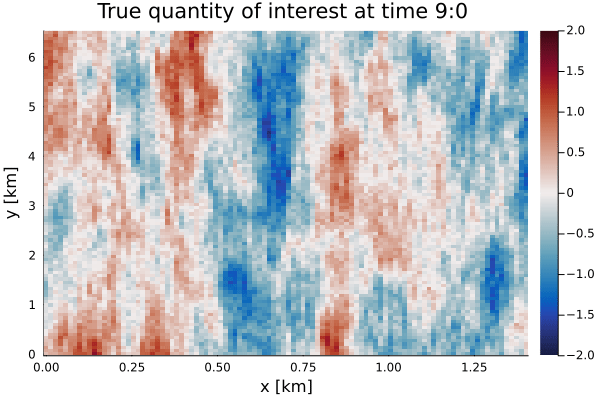

In [37]:
windfield = @animate for time_idx in 1:100:length(ts)
    heatmap(env_data.X, env_data.Y, env_data.W[:,:,time_idx], cmap=:balance)
    plot!(clims=(-2,2))
    xlabel!("x [km]");
    ylabel!("y [km]");
    title!("True quantity of interest at time $(Int(floor(ts[time_idx]))):$(Int(floor(mod(ts[time_idx],1)*60))) ")
end
gif(windfield)

┌ Info: Saved animation to
└ /home/kmgovind/Documents/adaptive-ocean-exploration-sim/results/fullsim/windw_domain.gif


Plots.AnimatedGif("/home/kmgovind/Documents/adaptive-ocean-exploration-sim/results/full_sim/wind_w_domain.gif")
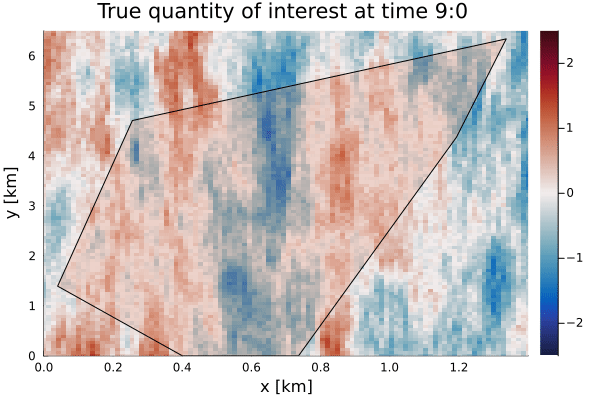

In [38]:
bounded_wind = @animate for time_idx in 1:100:length(ts)
    heatmap(env_data.X, env_data.Y, env_data.W[:,:,time_idx], cmap = :balance; plottype=:wx)
    polygon_vertices = hcat(JordanLakeDomain.convex_polygon.vertices, JordanLakeDomain.convex_polygon.vertices[:, 1])  # Close the polygon
    plot!(polygon_vertices[1, :], polygon_vertices[2, :], seriestype=:shape, fillalpha=0.2, label="")
    xlims!(0,1.4)
    ylims!(0,6.5)
    plot!(clims=(-2.5,2.5))
    xlabel!("x [km]");
    ylabel!("y [km]");
    title!("True quantity of interest at time $(Int(floor(ts[time_idx]))):$(Int(floor(mod(ts[time_idx],1)*60))) ")
end
gif(bounded_wind, "../results/full_sim/wind_w_domain.gif")


# Known Hyperparameter Simulation

## Controller Setup

In [39]:
# Create an ngpkf grid based on the data
σ_spatial = σ^2
# l_spatial = 1/λₓ_wrong
l_spatial = 1/λₛ

res_factor = 0.1 #l_spatial / sqrt(2.0)

kern = NGPKF.MaternKernel(σ_spatial, l_spatial)

ngp_grid_x = range(extrema(env_data.X)..., step= res_factor )
ngp_grid_y = range(extrema(env_data.Y)..., step= res_factor )
ngpkf_grid = NGPKF.NGPKFGrid(ngp_grid_x, ngp_grid_y, kern)

x0s = [@SVector[0.75, 3.0] for i=1:1]

1-element Vector{SVector{2, Float64}}:
 [0.75, 3.0]

In [40]:
target_q = 0.95

# Set the rated value matrix    
Nx, Ny = length(ngpkf_grid.xs), length(ngpkf_grid.ys)
target_q_mat = ones(Nx, Ny)
target_q_mat *= 0.0

x_domain = range(0, 1.4, length=Nx)
y_domain = range(0, 6.5, length=Ny)

for i in 1:length(x_domain)
    for j in 1:length(y_domain)
        p = [x_domain[i], y_domain[j]]
        if p ∈ JordanLakeDomain.convex_polygon.polygon
            target_q_mat[i, j] = 0.95
        end
    end
end

In [41]:
function Cfun(p, x)
    return kern(x, p)^2 / kern(p, p)
end
function Rfun(p, x)
    return (kern(x,x) - kern(x, p)^2 / kern(p, p) + 0.5^2)/(Δt)
end


S(p, x)  = Cfun(p, x)^2 / Rfun(p, x)
DxS(p, x) = ForwardDiff.gradient(xx-> S(p, xx), x)

DxS (generic function with 1 method)

In [42]:
using DifferentialEquations
using ForwardDiff

function clarity_prediction(t, q0, C, R, Q)

    k = C / sqrt(Q * R)
    
    q∞ = k / (1 + k)

    γ1 = q∞ - q0
    γ2 = γ1 * (k-1)
    γ3 = (k-1) * q0 - k

    return q∞ * ( 1 + 2 * γ1 / (γ2 + γ3 * exp(2 * k * Q * t)))
end

    
function clarity_time(q0, qf, C, R, Q; tmax=10.0)
    
    println("q0: $(q0)")
    println("qf: $(qf)")
    println("C: $(C)")
    println("R: $(R)")
    println("Q: $(Q)")
    
    if q0 >= qf
        return 0.0
    end

    k = C / sqrt(Q * R)
    println("k: $(k)")
    
    q∞ = k / (1 + k)
    println("q∞: $(q∞)")
    γ1 = q∞ - q0
    γ2 = γ1 * (k-1)
    γ3 = (k-1) * q0 - k

    
        
    if qf >= q∞
        return tmax
    end

    t = log((2*q∞*γ1 - qf*γ2 + q∞*γ2)/((qf - q∞)*γ3))/(2*k*Q)
    println("t: $(t)")

    return min(t, tmax)
end


C_ = Cfun(0,0)
R_ = Rfun(0,0)

k = (C_^2 / R_)
# q(t) = ((-k * t * q_0) + (k * t * q_0)) / ((-k * t * q_0) + (k * t) + 1)

function Clarity_delta_t(current_clarity, target_clarity)
    delta_t = (target_clarity - current_clarity) / ((target_clarity - 1) * k * (current_clarity - 1))
    return delta_t
end

function Clarity_delta_new(current_clarity, target_clarity)
    den = -target_clarity*k + k*current_clarity*target_clarity + k - k*current_clarity
    return delta_t = (target_clarity - current_clarity) / den
end


Clarity_delta_new (generic function with 1 method)

In [43]:
# Controller for weighted 2
using LinearAlgebra, StatsBase

function ergo_controller_weighted_2(t, xs, Mean, w_rated_val, convex_polygon;
        ergo_grid,
        ergo_q_map,
        traj,
        umax= 0.15, #30.0 * 60 / 1000,
        ΔT,
        kwargs...
        )
        
    target_q = 0.95

    # Set the rated value matrix    
    Nx, Ny = length(ngpkf_grid.xs), length(ngpkf_grid.ys)
    w_rated = ones(Nx, Ny)
    w_rated *= w_rated_val
  
#   Compute the target matrix 
    lambda_param = 0.05
    delta = -lambda_param*((Mean - w_rated).^2)
    q_target_temp = target_q*(exp.(delta)) 
    
    
    # Mask the matrix such that q_target is zero outisde the domain
    x_domain = range(0, 1.4, length=Nx)
    y_domain = range(0, 6.5, length=Ny)

    for i in 1:length(x_domain)
        for j in 1:length(y_domain)
            p = [x_domain[i], y_domain[j]]
            if (p ∈ convex_polygon.polygon) == false
                q_target_temp[i, j] = 0.0
            end
        end
    end

    # Get it in the right shape
    q_target_itp = linear_interpolation((ngpkf_grid.xs, ngpkf_grid.ys), q_target_temp, extrapolation_bc=Interpolations.Line())
    q_target_weighted = q_target_itp(ErgodicController.xs(ergo_grid), ErgodicController.ys(ergo_grid))     

    
    target_spatial_dist = zeros(size(ergo_q_map))
    Qp  = mean(σ_t.^2) # diagm(vec(σ_t .^2 * fuse_measurements_every_ΔT ))      
    
    for i in CartesianIndices(target_spatial_dist)
        if q_target_weighted[i] > ergo_q_map[i]
#             println("here in first cond")
            target_spatial_dist[i] = Clarity_delta_new(ergo_q_map[i], q_target_weighted[i])
        else
            target_spatial_dist[i] = 0.0
        end
    end
        
    u = [ErgodicController.controller_single_integrator_cvx_bound(ergo_grid, x, traj, target_spatial_dist, convex_polygon; umax=umax, do_boundary_correction=true) for x in xs]
    
#     println(u)
    
    return u, q_target_temp

end

ergo_controllers_weighted_2 = [ergo_controller_weighted_2 for i=1:length(x0s)]

1-element Vector{typeof(ergo_controller_weighted_2)}:
 ergo_controller_weighted_2 (generic function with 1 method)

## Generate SOC Target Profile

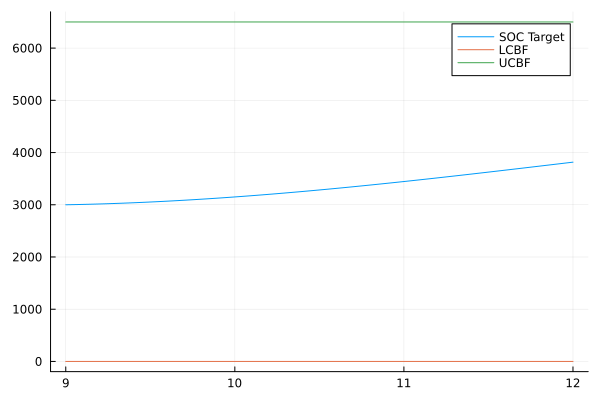

In [44]:
# Generate SOC_Target Profile
soc_begin = 3000
soc_end = 3500
lcbf = SoCController.compute_lcbf(ts, dt_hrs);
ucbf = SoCController.compute_ucbf(ts, dt_hrs);
soc_target = SoCController.generate_SOC_target(lcbf, ucbf,  soc_begin, soc_end, ts, dt_hrs);
plot(ts, soc_target, label="SOC Target")
plot!(ts, lcbf, label="LCBF")
plot!(ts,ucbf, label="UCBF")

## Simulate

In [45]:
# Initialize STGPKF
key_parameters_1 = STGPKF.KeyParameters(λₛ, σ, λₜ, 0.5, 2.0)
estimator_1 = STGPKF.Estimator()

Main.STGPKF.Estimator([0.0 0.0; 0.0 0.0; … ; 0.0 0.0; 0.0 0.0], [0.0 0.0 … 0.0 0.0; 0.0 0.0 … 0.0 0.0; … ; 0.0 0.0 … 0.0 0.0; 0.0 0.0 … 0.0 0.0;;; 0.0 0.0 … 0.0 0.0; 0.0 0.0 … 0.0 0.0; … ; 0.0 0.0 … 0.0 0.0; 0.0 0.0 … 0.0 0.0], [0.0 0.0; 0.0 0.0; … ; 0.0 0.0; 0.0 0.0], [0.0 0.0 … 0.0 0.0; 0.0 0.0 … 0.0 0.0; … ; 0.0 0.0 … 0.0 0.0; 0.0 0.0 … 0.0 0.0;;; 0.0 0.0 … 0.0 0.0; 0.0 0.0 … 0.0 0.0; … ; 0.0 0.0 … 0.0 0.0; 0.0 0.0 … 0.0 0.0])

In [46]:
include("../../../src/simulator_ST.jl")

Main.SimulatorST

In [16]:
fuse_measurements_every_ΔT = 5.0/(60*60) # hours
recompute_controller_every_ΔT = 5.0 / (120.0*60) # minutes
# σ_t = zeros(15, 66);
σ_t = zeros(66, 15);

w_rated_val = 1.5

@time res_ergo_hp =  SimulatorST.simulate_known_param(ts, x0s, soc_begin, ergo_controller_weighted_2, soc_target, w_rated_val, JordanLakeDomain.convex_polygon, key_parameters_1, estimator_1; 
    ngpkf_grid=ngpkf_grid, 
    EnvData=env_data, 
    σ_meas = 0.5,
    # σ_process= 0.075 * fuse_measurements_every_ΔT,
    Q_process = diagm(vec(σ_t .^2 * fuse_measurements_every_ΔT )) , 
    fuse_measurements_every_ΔT = fuse_measurements_every_ΔT, 
    recompute_controller_every_ΔT = recompute_controller_every_ΔT)

Progress:   0%|                                         |  ETA: N/A


u: [NaN, NaN]
New state: SVector{2, Float64}[[0.75, 3.0]]
u: [NaN, NaN]
New state: SVector{2, Float64}[[0.7458333333333333, 3.004166666666667]]
u: [NaN, NaN]
New state: SVector{2, Float64}[[0.7416666666666667, 3.0083333333333337]]
Inside prediction of NGP
u: [NaN, NaN]
New state: SVector{2, Float64}[[0.7375, 3.0125000000000006]]
u: [NaN, NaN]
New state: SVector{2, Float64}[[0.7333333333333334, 3.0166666666666675]]
u: [NaN, NaN]
New state: SVector{2, Float64}[[0.7291666666666667, 3.0208333333333344]]
Inside prediction of NGP
u: [NaN, NaN]
New state: SVector{2, Float64}[[0.7250000000000001, 3.0250000000000012]]
u: [NaN, NaN]
New state: SVector{2, Float64}[[0.7208333333333334, 3.029166666666668]]
Inside prediction of NGP
u: [NaN, NaN]
New state: SVector{2, Float64}[[0.7166666666666668, 3.033333333333335]]
u: [NaN, NaN]
New state: SVector{2, Float64}[[0.7125000000000001, 3.037500000000002]]
u: [NaN, NaN]
New state: SVector{2, Float64}[[0.7083333333333335, 3.0416666666666687]]
Inside predic

Progress:   1%|▎                                        |  ETA: 0:11:32


[NaN, NaN]
New state: SVector{2, Float64}[[0.6958333333333335, 3.095833333333338]]
u: [NaN, NaN]
New state: SVector{2, Float64}[[0.7000000000000002, 3.100000000000005]]
u: [NaN, NaN]
New state: SVector{2, Float64}[[0.6958333333333335, 3.104166666666672]]
Inside prediction of NGP
u: [NaN, NaN]
New state: SVector{2, Float64}[[0.7000000000000002, 3.1083333333333387]]
u: [NaN, NaN]
New state: SVector{2, Float64}[[0.6958333333333335, 3.1125000000000056]]
u: [NaN, NaN]
New state: SVector{2, Float64}[[0.7000000000000002, 3.1166666666666725]]
Inside prediction of NGP
u: [NaN, NaN]
New state: SVector{2, Float64}[[0.6958333333333335, 3.1208333333333393]]
u: [NaN, NaN]
New state: SVector{2, Float64}[[0.7000000000000002, 3.125000000000006]]
u: [NaN, NaN]
New state: SVector{2, Float64}[[0.6958333333333335, 3.129166666666673]]
Inside prediction of NGP
u: [NaN, NaN]
New state: SVector{2, Float64}[[0.7000000000000002, 3.13333333333334]]
u: [NaN, NaN]
New state: SVector{2, Float64}[[0.6958333333333335,

Progress:   1%|▍                                        |  ETA: 0:08:01


...

[NaN, NaN]
New state: SVector{2, Float64}[[0.7000000000000002, 3.2500000000000124]]
u: [NaN, NaN]
New state: SVector{2, Float64}[[0.6958333333333335, 3.2458333333333456]]
u: [NaN, NaN]
New state: SVector{2, Float64}[[0.7000000000000002, 3.2500000000000124]]
Inside prediction of NGP
u: [NaN, NaN]
New state: SVector{2, Float64}[[0.6958333333333335, 3.2458333333333456]]
u: [NaN, NaN]
New state: SVector{2, Float64}[[0.7000000000000002, 3.2500000000000124]]
u: [NaN, NaN]
New state: SVector{2, Float64}[[0.6958333333333335, 3.2458333333333456]]
Inside prediction of NGP
u: [NaN, NaN]
New state: SVector{2, Float64}[[0.7000000000000002, 3.2500000000000124]]
u: [NaN, NaN]
New state: SVector{2, Float64}[[0.6958333333333335, 3.2458333333333456]]
u: [NaN, NaN]
New state: SVector{2, Float64}[[0.7000000000000002, 3.2500000000000124]]
Inside prediction of NGP
u: [NaN, NaN]
New state: SVector{2, Float64}[[0.6958333333333335, 3.2458333333333456]]
u: [NaN, NaN]
New state: SVector{2, Float64}[[0.7000000000

Progress:  41%|████████████████▉                        |  ETA: 0:05:31


u: [NaN, NaN]
New state: SVector{2, Float64}[[0.7000000000000002, 3.2500000000000124]]
u: [NaN, NaN]
New state: SVector{2, Float64}[[0.6958333333333335, 3.2458333333333456]]
u: [NaN, NaN]
New state: SVector{2, Float64}[[0.7000000000000002, 3.2500000000000124]]
Inside prediction of NGP
u: [NaN, NaN]
New state: SVector{2, Float64}[[0.6958333333333335, 3.2458333333333456]]
u: [NaN, NaN]
New state: SVector{2, Float64}[[0.7000000000000002, 3.2500000000000124]]
u: [NaN, NaN]
New state: SVector{2, Float64}[[0.6958333333333335, 3.2458333333333456]]
Inside prediction of NGP
u: [NaN, NaN]
New state: SVector{2, Float64}[[0.7000000000000002, 3.2500000000000124]]
u: [NaN, NaN]
New state: SVector{2, Float64}[[0.6958333333333335, 3.2458333333333456]]
u: [NaN, NaN]
New state: SVector{2, Float64}[[0.7000000000000002, 3.2500000000000124]]
Inside prediction of NGP
u: [NaN, NaN]
New state: SVector{2, Float64}[[0.6958333333333335, 3.2458333333333456]]
u: [NaN, NaN]
New state: SVector{2, Float64}[[0.7000000

Progress:  42%|█████████████████▏                       |  ETA: 0:06:12


u: [NaN, NaN]
New state: SVector{2, Float64}[[0.7000000000000002, 3.2500000000000124]]
u: [NaN, NaN]
New state: SVector{2, Float64}[[0.6958333333333335, 3.2458333333333456]]
Inside prediction of NGP
u: [NaN, NaN]
New state: SVector{2, Float64}[[0.7000000000000002, 3.2500000000000124]]
u: [NaN, NaN]
New state: SVector{2, Float64}[[0.6958333333333335, 3.2458333333333456]]
Inside prediction of NGP
u: [NaN, NaN]
New state: SVector{2, Float64}[[0.7000000000000002, 3.2500000000000124]]
u: [NaN, NaN]
New state: SVector{2, Float64}[[0.6958333333333335, 3.2458333333333456]]
u: [NaN, NaN]
New state: SVector{2, Float64}[[0.7000000000000002, 3.2500000000000124]]
Inside prediction of NGP
u: [NaN, NaN]
New state: SVector{2, Float64}[[0.6958333333333335, 3.2458333333333456]]
u: [NaN, NaN]
New state: SVector{2, Float64}[[0.7000000000000002, 3.2500000000000124]]
u: [NaN, NaN]
New state: SVector{2, Float64}[[0.6958333333333335, 3.2458333333333456]]
Inside prediction of NGP
u: [NaN, NaN]
New state: SVect

In [ ]:
if any(isnan.([1,NaN]))
    println("hi")
end

In [ ]:
plot()
polygon_vertices = hcat(JordanLakeDomain.convex_polygon.vertices, JordanLakeDomain.convex_polygon.vertices[:, 1])
heatmap(env_data.X, env_data.Y, env_data.W[:,:,1], cmap = :balance; plottype=:wx)
plot!(polygon_vertices[1, :], polygon_vertices[2, :], seriestype=:shape, fillalpha=0.0, label="", lw = 3, linecolor = "green")
for i=1:length(x0s)
    x = [r[i][1] for r in res_ergo_hp.xs]
    
    y = [r[i][2] for r in res_ergo_hp.xs]
    plot!(x,y, linewidth=3, color=:black, label = "")
end
plot!()

title!("q_T= 0.95 for exponential weighted coverage")

In [ ]:
@gif for n = 1:100:length(res_ergo_hp.ts)
    plot()
    heatmap(env_data.X, env_data.Y, env_data.W[:,:,n]', cmap = :balance; plottype=:wx)
    plot!(polygon_vertices[1, :], polygon_vertices[2, :], seriestype=:shape, fillalpha=0.0, label="", lw = 2, linecolor = "green")
    for i=1:length(x0s)
        x = [r[i][1] for r in res_ergo_hp.xs[1:n]]
        y = [r[i][2] for r in res_ergo_hp.xs[1:n]]
        plot!(x, y, linewidth=3, color=:black)
    end
    plot!()
end

In [ ]:
for time_idx in 1:res_ergo_hp.w_hat_ts
    res_ergo_hp.w_hat[time_idx]
end

In [ ]:
plot(ts, res_ergo_hp.bs[2:end], label="SOC")
plot!(ts, soc_target, label="SOC Target")

In [ ]:
# Collect speeds
u1 = Float64[]
u2 = Float64[]
speed = Float64[]

for i=1:length(res_ergo_hp.us)
    push!(u1, res_ergo_hp.us[i][1][1])
    push!(u2, res_ergo_hp.us[i][1][2])
    push!(speed, norm(res_ergo_hp.us[i][1]))
end

# Speed vs time plot
plot(ts, res_ergo_hp.speeds, label="Speed Controller Command")
plot!(ts, speed, label="Executed Speed")
ylims!(0., 2.5)
title!("Speed vs Time")
xlabel!("Time [hr, 12 = noon]")
ylabel!("Speed [m/s]")
plot!(legend=:right)


In [ ]:
@gif for n = 1:100:length(res_ergo_hp.ts)
    heatmap(ngpkf_grid, res_ergo_hp.w_hats[n], clims=(0, 1.0), plotstd=true)
end

In [ ]:
target_maps_exp = [res_ergo_hp.q_target_maps[1],]

for i=2:124:length(res_ergo_hp.q_target_maps)
    push!(target_maps_exp,res_ergo_hp.q_target_maps[i])
end

@gif for i=1:length(res_ergo_hp.ergo_q_maps)
    p0 = heatmap(env_data.X, env_data.Y, env_data.W[:,:,i]', cmap = :balance; plottype=:wx, title = "True windfield")
    p2 = heatmap(target_maps_exp[i]', title = "Target Clarity Exp")
    plot(p0, p2, layout=@layout[a c], size=(1500, 300))
#     title!("Weighted coverage")
end

# Hyperparameter Estimation Simulation

In [ ]:
# Create an ngpkf grid based on the data
σ_spatial = σ^2
# l_spatial = 1/λₓ_wrong
l_spatial = 1/λₛ

res_factor = 0.1 #l_spatial / sqrt(2.0)

kern = NGPKF.MaternKernel(σ_spatial, l_spatial)

ngp_grid_x = range(extrema(env_data.X)..., step= res_factor )
ngp_grid_y = range(extrema(env_data.Y)..., step= res_factor )
ngpkf_grid = NGPKF.NGPKFGrid(ngp_grid_x, ngp_grid_y, kern)

x0s = [@SVector[0.75, 3.0] for i=1:1]

In [ ]:
target_q = 0.95

# Set the rated value matrix    
Nx, Ny = length(ngpkf_grid.xs), length(ngpkf_grid.ys)
target_q_mat = ones(Nx, Ny)
target_q_mat *= 0.0

x_domain = range(0, 1.4, length=Nx)
y_domain = range(0, 6.5, length=Ny)

for i in 1:length(x_domain)
    for j in 1:length(y_domain)
        p = [x_domain[i], y_domain[j]]
        if p ∈ JordanLakeDomain.convex_polygon.polygon
            target_q_mat[i, j] = 0.95
        end
    end
end

In [ ]:
function Cfun(p, x)
    return kern(x, p)^2 / kern(p, p)
end
function Rfun(p, x)
    return (kern(x,x) - kern(x, p)^2 / kern(p, p) + 0.5^2)/(Δt)
end


S(p, x)  = Cfun(p, x)^2 / Rfun(p, x)
DxS(p, x) = ForwardDiff.gradient(xx-> S(p, xx), x)

In [ ]:
using DifferentialEquations
using ForwardDiff

function clarity_prediction(t, q0, C, R, Q)

    k = C / sqrt(Q * R)
    
    q∞ = k / (1 + k)

    γ1 = q∞ - q0
    γ2 = γ1 * (k-1)
    γ3 = (k-1) * q0 - k

    return q∞ * ( 1 + 2 * γ1 / (γ2 + γ3 * exp(2 * k * Q * t)))
end

    
function clarity_time(q0, qf, C, R, Q; tmax=10.0)
    
    println("q0: $(q0)")
    println("qf: $(qf)")
    println("C: $(C)")
    println("R: $(R)")
    println("Q: $(Q)")
    
    if q0 >= qf
        return 0.0
    end

    k = C / sqrt(Q * R)
    println("k: $(k)")
    
    q∞ = k / (1 + k)
    println("q∞: $(q∞)")
    γ1 = q∞ - q0
    γ2 = γ1 * (k-1)
    γ3 = (k-1) * q0 - k

    
        
    if qf >= q∞
        return tmax
    end

    t = log((2*q∞*γ1 - qf*γ2 + q∞*γ2)/((qf - q∞)*γ3))/(2*k*Q)
    println("t: $(t)")

    return min(t, tmax)
end


C_ = Cfun(0,0)
R_ = Rfun(0,0)

k = (C_^2 / R_)
# q(t) = ((-k * t * q_0) + (k * t * q_0)) / ((-k * t * q_0) + (k * t) + 1)

function Clarity_delta_t(current_clarity, target_clarity)
    delta_t = (target_clarity - current_clarity) / ((target_clarity - 1) * k * (current_clarity - 1))
    return delta_t
end

function Clarity_delta_new(current_clarity, target_clarity)
    den = -target_clarity*k + k*current_clarity*target_clarity + k - k*current_clarity
    return delta_t = (target_clarity - current_clarity) / den
end


In [ ]:
# Controller for weighted 2
using LinearAlgebra, StatsBase

function ergo_controller_weighted_2(t, xs, Mean, w_rated_val, convex_polygon;
        ergo_grid,
        ergo_q_map,
        traj,
        umax= 0.15, #30.0 * 60 / 1000,
        ΔT,
        kwargs...
        )
        
    target_q = 0.95

    # Set the rated value matrix    
    Nx, Ny = length(ngpkf_grid.xs), length(ngpkf_grid.ys)
    w_rated = ones(Nx, Ny)
    w_rated *= w_rated_val
  
#   Compute the target matrix 
    lambda_param = 0.05
    delta = -lambda_param*((Mean - w_rated).^2)
    q_target_temp = target_q*(exp.(delta)) 
    
    
    # Mask the matrix such that q_target is zero outisde the domain
    x_domain = range(0, 1.4, length=Nx)
    y_domain = range(0, 6.5, length=Ny)

    for i in 1:length(x_domain)
        for j in 1:length(y_domain)
            p = [x_domain[i], y_domain[j]]
            if (p ∈ convex_polygon.polygon) == false
                q_target_temp[i, j] = 0.0
            end
        end
    end

    # Get it in the right shape
    q_target_itp = linear_interpolation((ngpkf_grid.xs, ngpkf_grid.ys), q_target_temp, extrapolation_bc=Interpolations.Line())
    q_target_weighted = q_target_itp(ErgodicController.xs(ergo_grid), ErgodicController.ys(ergo_grid))     

    
    target_spatial_dist = zeros(size(ergo_q_map))
    Qp  = mean(σ_t.^2) # diagm(vec(σ_t .^2 * fuse_measurements_every_ΔT ))      
    
    for i in CartesianIndices(target_spatial_dist)
        if q_target_weighted[i] > ergo_q_map[i]
#             println("here in first cond")
            target_spatial_dist[i] = Clarity_delta_new(ergo_q_map[i], q_target_weighted[i])
        else
            target_spatial_dist[i] = 0.0
        end
    end
        
    u = [ErgodicController.controller_single_integrator_cvx_bound(ergo_grid, x, traj, target_spatial_dist, convex_polygon; umax=umax, do_boundary_correction=true) for x in xs]
    
#     println(u)
    
    return u, q_target_temp

end

ergo_controllers_weighted_2 = [ergo_controller_weighted_2 for i=1:length(x0s)]

## Generate SOC Target Profile

In [ ]:
# Generate SOC_Target Profile
soc_begin = 3000
soc_end = 3500
lcbf = SoCController.compute_lcbf(ts, dt_hrs);
ucbf = SoCController.compute_ucbf(ts, dt_hrs);
soc_target = SoCController.generate_SOC_target(lcbf, ucbf,  soc_begin, soc_end, ts, dt_hrs);
plot(ts, soc_target, label="SOC Target")
plot!(ts, lcbf, label="LCBF")
plot!(ts,ucbf, label="UCBF")

## Simulate

In [ ]:
# Initialize STGPKF
key_parameters_1 = STGPKF.KeyParameters(λₛ, σ, λₜ, 0.5, Δt)
estimator_1 = STGPKF.Estimator()

In [ ]:
fuse_measurements_every_ΔT = 5.0/60 # minutes
recompute_controller_every_ΔT = 5.0 / (120.0*60) # minutes
σ_t = zeros(15, 66);

w_rated_val = 0.4

@time res_ergo_est =  SimulatorST.simulate_param_est(ts, x0s, soc_begin, ergo_controller_weighted_2, soc_target, w_rated_val, JordanLakeDomain.convex_polygon, key_parameters_1, estimator_1; 
    ngpkf_grid=ngpkf_grid, 
    EnvData=env_data, 
    σ_meas = 0.5,
    # σ_process= 0.075 * fuse_measurements_every_ΔT,
    Q_process = diagm(vec(σ_t .^2 * fuse_measurements_every_ΔT )) , 
    fuse_measurements_every_ΔT = fuse_measurements_every_ΔT, 
    recompute_controller_every_ΔT = recompute_controller_every_ΔT)

In [ ]:
plot()
polygon_vertices = hcat(JordanLakeDomain.convex_polygon.vertices, JordanLakeDomain.convex_polygon.vertices[:, 1])
heatmap(env_data.X, env_data.Y, env_data.W[:,:,1], cmap = :balance; plottype=:wx)
plot!(polygon_vertices[1, :], polygon_vertices[2, :], seriestype=:shape, fillalpha=0.0, label="", lw = 3, linecolor = "green")
for i=1:length(x0s)
    x = [r[i][1] for r in res_ergo_est.xs]
    
    y = [r[i][2] for r in res_ergo_est.xs]
    plot!(x,y, linewidth=3, color=:black, label = "")
end
plot!()

title!("q_T= 0.95 for exponential weighted coverage")

In [ ]:
@gif for n = 1:100:length(res_ergo_est.ts)
    plot()
    heatmap(env_data.X, env_data.Y, env_data.W[:,:,n]', cmap = :balance; plottype=:wx)
    plot!(polygon_vertices[1, :], polygon_vertices[2, :], seriestype=:shape, fillalpha=0.0, label="", lw = 2, linecolor = "green")
    for i=1:length(x0s)
        x = [r[i][1] for r in res_ergo_est.xs[1:n]]
        y = [r[i][2] for r in res_ergo_est.xs[1:n]]
        plot!(x, y, linewidth=3, color=:black)
    end
    title!("Time: $(Int(floor(ts[n]))):$(Int(floor(mod(ts[n],1)*60)))")
    plot!(clims=(-2.5,2.5))
end

In [ ]:
plot(ts, res_ergo_est.bs[2:end], label="SOC")
plot!(ts, soc_target, label="SOC Target")

In [ ]:
# Collect speeds
u1 = Float64[]
u2 = Float64[]
speed = Float64[]

for i=1:length(res_ergo_est.us)
    push!(u1, res_ergo_est.us[i][1][1])
    push!(u2, res_ergo_est.us[i][1][2])
    push!(speed, norm(res_ergo_est.us[i][1]))
end

# Speed vs time plot
plot(ts, res_ergo_est.speeds, label="Speed Controller Command")
plot!(ts, speed, label="Executed Speed")
ylims!(0., 2.5)
title!("Speed vs Time")
xlabel!("Time [hr, 12 = noon]")
ylabel!("Speed [m/s]")
plot!(legend=:right)


In [ ]:
@gif for n = 1:100:length(res_ergo_est.ts)
    heatmap(ngpkf_grid, res_ergo_est.w_hats[n], clims=(0, 1.0), plotstd=true)
end

In [ ]:
target_maps_exp = [res_ergo_est.q_target_maps[1],]

for i=2:124:length(res_ergo_est.q_target_maps)
    push!(target_maps_exp,res_ergo_est.q_target_maps[i])
end

@gif for i=1:length(res_ergo_est.ergo_q_maps)
    p0 = heatmap(env_data.X, env_data.Y, env_data.W[:,:,i]', cmap = :balance; plottype=:wx, title = "True windfield")
    p2 = heatmap(target_maps_exp[i]', title = "Target Clarity Exp")
    plot(p0, p2, layout=@layout[a c], size=(1500, 300))
#     title!("Weighted coverage")
end

In [ ]:
res_ergo_est.λx_s

In [ ]:
res_ergo_est.λt_s

In [ ]:
res_ergo_est.σ_s